In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_train.csv")
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [2]:
print(df.shape)


(60000, 785)


# Labels and its meaning



| Label | Description |
| :--- | :--- |
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |



# Viewing the dataset

Labels: [2, 9, 6, 0, 3, 4, 4, 5, 4, 8]


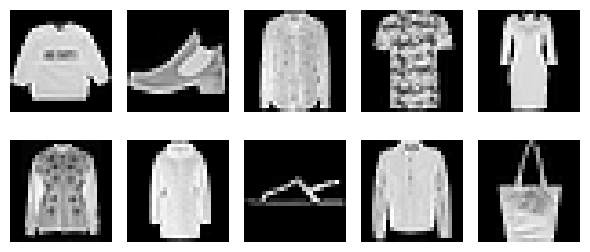

In [3]:
import matplotlib.pyplot as plt

labels = df["label"].head(10).to_list()
print(f"Labels: {labels}")

fig, axes = plt.subplots(2, 5, figsize=(6, 3))
axes = axes.flatten()

for i in range(10):
    img_raw = df.drop(columns=['label']).iloc[i].values
    img_shaped = img_raw.reshape(28,28)
    axes[i].imshow(img_shaped, cmap='gray')
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# Check if test has labels

If it didnt, I'll have to use train and split a test there
However its not needed because theres labels in test.csv

In [4]:
df2 = pd.read_csv("/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_test.csv")
df2.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# Splitting the labels and creating the train test variables

In [5]:
train = df.copy() # Originally 60,000, 785
train_labels = train.pop("label") # removes the label column from the set
train = train.T # now 784, 60,000 where every column is an image

test = df2.copy() # Originally 10,000, 785
test_labels = test.pop("label") # removes the label column from the set
test = test.T # now 784, 10,000
test.shape

(784, 10000)

# Initializing the weights and biases